# Étude de cas — Analyse Big Data des accidents de la route avec PySpark

**Cours :** Fondements et Application de Big Data

**Objectif :** refaire l'étude *« Big Data Analysis of Road Crash Data using PySpark with PySpark Tutorial »*
(Rakesh Nain, 2021 — [article](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588)),
qui analyse les accidents de la route en **Australie-Méridionale de 2012 à 2019** avec les trois API de Spark : **RDD**, **DataFrame** et **Spark SQL**.

### Le problème

Les autorités routières disposent de centaines de milliers d'enregistrements d'accidents et de véhicules impliqués. On veut répondre
à des questions concrètes de sécurité routière — qui est impliqué, où, quand, et surtout : **les accidents sont-ils plus graves quand le
conducteur a consommé de la drogue ou de l'alcool ?** — avec un outil capable de passer à l'échelle, Spark.

### Démarche

1. comprendre et contrôler les données ;
2. reproduire les requêtes de l'article avec l'API **RDD**, puis l'API **DataFrame** ;
3. écrire les mêmes requêtes avec les **trois API** et vérifier qu'elles donnent **exactement le même résultat** (tests) ;
4. comparer les temps d'exécution des trois API ;
5. aller plus loin que l'article (évolution annuelle, heure et jour, vitesse) ;
6. relever de façon critique les **erreurs de l'article** que la reproduction a mises en évidence ;
7. conclure.

Le code réutilisable est dans `src/road_crash.py` (chaque requête en trois versions) et les tests dans `tests/test_road_crash.py`.

## 0. Environnement

Comme au TP2, PySpark tourne dans un **conteneur Linux** (Python 3.12, OpenJDK 17, PySpark 4.2.0), dans lequel ce notebook est exécuté :
sous Windows natif, chaque tâche Spark relance un interpréteur Python, ce qui rend l'API RDD inutilisable sur ce poste.

```bash
docker build -t road-crash-pyspark:4.2.0 .
python src/telecharger_donnees.py                     # données -> data/ (≈ 77 Mo)
docker run --rm -p 8888:8888 -v "%cd%:/work" road-crash-pyspark:4.2.0 jupyter lab --ip=0.0.0.0 --allow-root --no-browser
```

In [1]:
import os, sys, time, platform, subprocess, statistics
sys.path.insert(0, os.path.abspath("src"))
import pyspark
print("OS      :", platform.platform())
print("Python  :", sys.version.split()[0], "| PySpark :", pyspark.__version__)
print("Java    :", subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])
print("CPU     :", os.cpu_count(), "cœurs visibles")

OS      : Linux-5.15.167.4-microsoft-standard-WSL2-x86_64-with-glibc2.36
Python  : 3.12.15 | PySpark : 4.2.0


Java    : openjdk version "17.0.20.1" 2026-08-18
CPU     : 8 cœurs visibles


## 1. Les données

Source : *Department of Planning, Transport and Infrastructure* (DPTI) d'Australie-Méridionale, portail https://data.sa.gov.au.
On utilise la copie fournie par l'auteur (même découpage en dossiers), téléchargée par `src/telecharger_donnees.py`
et figée sur un commit précis de son dépôt. Deux jeux de données, un fichier CSV par année :

| Jeu | Grain | Colonnes principales |
|---|---|---|
| **Crash** (`crash_data/`) | **un accident** par ligne (`REPORT_ID` unique) | lieu (`Suburb`, `LGA Name`, coordonnées), date (`Year`, `Month`, `Day` = jour de la semaine, `Time`), `Total Cas` (victimes), `Total Fats` (morts), `Area Speed`, `Crash Type`, `CSEF Severity`, `DUI Involved` (alcool), `Drugs Involved` |
| **Units** (`units_data/`) | **un véhicule / usager impliqué** par ligne | `REPORT_ID` (clé de jointure), `Unit Type`, `Veh Year`, `Veh Reg State`, `Sex`, `Age`, `Lic State`, `Licence Type` |

**Gravité (`CSEF Severity`)** : `1: PDO` = dégâts matériels seuls (*property damage only*), `2: MI` = blessure légère, `3: SI` = blessure grave, `4: Fatal` = accident mortel.

*Confidentialité :* le jour exact de l'accident n'est pas publié ; une date s'affiche au format **Année-Mois-JourDeLaSemaine** (ex. `2017-January-Sunday`).
Certaines valeurs sont masquées par le fournisseur : `XXX` pour l'âge, `XXXX` pour l'année du véhicule ou le code postal.

In [2]:
import road_crash as rc
from pyspark.sql import functions as F
t0 = time.perf_counter()
spark = rc.creer_session("local[*]", nom="Road Crash Data")
sc = spark.sparkContext
print(f"SparkSession en {time.perf_counter() - t0:.1f} s — master {sc.master}, parallélisme {sc.defaultParallelism}")
for d in ["crash_data", "units_data"]:
    fichiers = sorted(os.listdir(f"data/{d}"))
    print(d, ":", len(fichiers), "fichiers,", round(sum(os.path.getsize(f"data/{d}/{f}") for f in fichiers) / 1e6, 1), "Mo —",
          fichiers[0], "…", fichiers[-1])

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/16 08:31:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


SparkSession en 45.7 s — master local[*], parallélisme 8
crash_data : 8 fichiers, 42.5 Mo — 2012_DATA_SA_Crash.csv … 2019_DATA_SA_Crash.csv


units_data : 8 fichiers, 37.7 Mo — 2012_DATA_SA_Units.csv … 2019_DATA_SA_Units.csv


## 2. Analyse avec les RDD

Un **RDD** (*Resilient Distributed Dataset*) est une collection immuable d'objets Python, découpée en **partitions** traitées en parallèle.
On le crée avec `parallelize()` (à partir d'une collection Python) ou `textFile()` (une ligne de fichier = un élément).

In [3]:
rdd = sc.parallelize(range(10))
print("Partitions par défaut :", rdd.getNumPartitions())
rdd = sc.parallelize(range(10), 5)
print("Partitions demandées  :", rdd.getNumPartitions(), "->", rdd.glom().collect())

Partitions par défaut : 8


Partitions demandées  : 5 -> [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]


### 2.1 Chargement et en-têtes

`textFile("…/*.csv")` lit les 8 fichiers annuels d'un coup. Chaque fichier contient une ligne d'en-tête, **identique d'une année à l'autre**,
qu'on retire avec un `filter`.

In [4]:
units_rdd, crash_rdd = rc.charger_rdd(spark)
print("Units :", units_rdd.count(), "enregistrements,", units_rdd.getNumPartitions(), "partitions")
print("Crash :", crash_rdd.count(), "enregistrements,", crash_rdd.getNumPartitions(), "partitions")
print(crash_rdd.take(2))

Units : 272591 enregistrements, 8 partitions


Crash : 127672 enregistrements, 8 partitions


['"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"', '"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"']


### 2.2 Découper une ligne CSV : le piège du `split(',')`

L'article découpe chaque ligne avec `ligne.split(',')`. C'est faux dès qu'un champ **entre guillemets contient une virgule** —
et il y en a dans ce jeu de données : on le vérifie en comparant avec le module `csv` de Python, qui respecte les guillemets.

In [5]:
nb_col = len(rc.CRASH_COLS)
casses = crash_rdd.filter(lambda l: len(rc.parser_naif(l)) != nb_col)
print(f"Lignes Crash mal découpées par split(','): {casses.count()} sur {crash_rdd.count()} "
      f"({100 * casses.count() / crash_rdd.count():.1f} %)")
print("Lignes Units mal découpées :", units_rdd.filter(lambda l: len(rc.parser_naif(l)) != len(rc.UNITS_COLS)).count())

champs = (crash_rdd.map(rc.parser_csv)
          .flatMap(lambda r: [(rc.CRASH_COLS[i], v) for i, v in enumerate(r) if "," in v])
          .countByValue())
for (colonne, valeur), n in sorted(champs.items(), key=lambda x: -x[1]):
    print(f"  {n:>6} × {colonne:<17} = {valeur!r}")

Lignes Crash mal découpées par split(','): 21379 sur 127672 (16.7 %)


Lignes Units mal découpées : 0


   10933 × Horizontal Align  = 'CURVED, VIEW OPEN'
    5566 × LGA Name          = 'CC OF NORWOOD,PAYNEHAM & ST PETERS'
    4518 × Horizontal Align  = 'CURVED, VIEW OBSCURED'
     878 × Other Feat        = 'Bridge, Culvert, Causeway'


In [6]:
# Conséquence : pour ces lignes, les colonnes suivantes sont décalées. Exemple sur "Total Cas" et la date :
comparaison = crash_rdd.map(lambda l: (rc.parser_csv(l), rc.parser_naif(l)))
faux_cas = comparaison.filter(lambda p: p[0][rc.C["Total Cas"]] != p[1][rc.C["Total Cas"]]).count()
faux_annee = comparaison.filter(lambda p: p[0][rc.C["Year"]] != p[1][rc.C["Year"]]).count()
print("Accidents dont 'Total Cas' serait lu de travers :", faux_cas)
print("Accidents dont l'année serait lue de travers    :", faux_annee)
print(comparaison.filter(lambda p: p[0][rc.C["Year"]] != p[1][rc.C["Year"]])
      .map(lambda p: (p[0][rc.C["Year"]], p[1][rc.C["Year"]])).first(), "  <- (vraie valeur, valeur lue par split)")

Accidents dont 'Total Cas' serait lu de travers : 5388
Accidents dont l'année serait lue de travers    : 5566


('2012', '0')   <- (vraie valeur, valeur lue par split)


Dans toute la suite, les RDD utilisent `rc.parser_csv` (module `csv`). Les DataFrames n'ont pas ce problème :
`spark.read.csv(..., escape='"')` gère les guillemets.

### 2.3 Partitionnement personnalisé

Spark répartit les données sans critère métier. On peut imposer un partitionnement : ici, **une partition pour les véhicules immatriculés
en Australie-Méridionale (SA), une pour tous les autres**. On construit un RDD clé-valeur (état d'immatriculation, reste de la ligne)
puis on applique `partitionBy` avec notre fonction de hachage.

In [7]:
units_etat_rdd = units_rdd.map(rc.parser_csv).map(lambda r: (r[rc.U["Veh Reg State"]], r))

def hash_sa(cle):
    return 0 if cle == "SA" else 1

sa_rdd = units_etat_rdd.partitionBy(2, hash_sa)
print("Nombre de partitions :", sa_rdd.getNumPartitions())
for i, n in enumerate(sa_rdd.glom().map(len).collect()):
    print(f"Partition {i} : {n} enregistrements")

Nombre de partitions : 2


Partition 0 : 218366 enregistrements
Partition 1 : 54225 enregistrements


On retrouve exactement les effectifs de l'article (218 366 / 54 225). L'article indique partitionner sur la colonne `Lic State`
(État du **permis**), mais son code utilise l'index 3, qui est en réalité **`Veh Reg State`** (État d'**immatriculation** du véhicule) :
avec `Lic State`, la partition SA ne compterait que 198 646 enregistrements.

### 2.4 Âge moyen des personnes impliquées, par sexe

On ne garde que `Male`/`Female` et les âges numériques (`XXX` = âge masqué, vide = non renseigné). Plutôt que `groupByKey`
(comme l'article), on utilise `reduceByKey` sur des couples (somme, effectif) : l'agrégation se fait d'abord dans chaque partition.

In [8]:
print(rc.age_moyen_rdd(units_rdd))

{'Male': 40.8, 'Female': 40.08}


L'âge moyen des hommes (40,8 ans) et des femmes (40,1 ans) impliqués est quasiment identique — même résultat que l'article.

### 2.5 Véhicules les plus anciens et les plus récents impliqués

In [9]:
annees_rdd = (units_rdd.map(rc.parser_csv)
              .filter(lambda r: r[rc.U["Veh Year"]].isdigit())
              .map(lambda r: (int(r[rc.U["Veh Year"]]), (r[rc.U["Veh Reg State"]], r[rc.U["Unit Type"]]))))
print("5 plus anciens :", annees_rdd.sortByKey(ascending=True).take(5))
print("5 plus récents :", annees_rdd.sortByKey(ascending=False).take(5))
print("Véhicules déclarés de 1900 :", annees_rdd.filter(lambda kv: kv[0] == 1900).count(),
      "| avant 1950 :", annees_rdd.filter(lambda kv: kv[0] < 1950).count())

5 plus anciens : [(1900, ('VIC', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle'))]


5 plus récents : [(2019, ('SA', 'Station Wagon')), (2019, ('SA', 'OMNIBUS')), (2019, ('SA', 'Motor Cars - Sedan')), (2019, ('SA', 'Station Wagon')), (2019, ('SA', 'SEMI TRAILER'))]


Véhicules déclarés de 1900 : 14 | avant 1950 : 34


`take(5)` après le tri évite le `collect()[0:5]` de l'article, qui rapatrie **tout** le RDD trié (≈ 220 000 éléments) sur le driver
pour n'en garder que 5. L'année **1900** est presque certainement une valeur par défaut de saisie (motos « de 1900 ») : une analyse
sérieuse de l'âge des véhicules devrait l'exclure.

## 3. Analyse avec les DataFrames

Un **DataFrame** est une table distribuée avec des colonnes nommées et typées. Les requêtes sont déclaratives et optimisées par **Catalyst** ;
elles s'exécutent dans la JVM, sans faire passer les données par Python.

In [10]:
units_df, crash_df = rc.charger_df(spark)
rc.enregistrer_vues(units_df, crash_df)
crash_df.printSchema()
print("Crash :", crash_df.count(), "accidents | Units :", units_df.count(), "usagers / véhicules")

root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: integer (nullable = true)
 |-- Total Cas: integer (nullable = true)
 |-- Total Fats: integer (nullable = true)
 |-- Total SI: integer (nullable = true)
 |-- Total MI: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: string (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-- DayNight: string (nullable = true)
 |-- Crash Type: string (nullable = true)


Crash : 127672 accidents | Units : 272591 usagers / véhicules


### 3.1 Contrôle qualité : valeurs manquantes ou masquées

In [11]:
def manquants(df, colonnes, masques=("XXX", "XXXX", "UNKNOWN", "Unknown")):
    total = df.count()
    lignes = df.select([F.round(100 * F.sum(F.when(F.col(c).isNull() | F.trim(F.col(c)).isin(*masques), 1).otherwise(0)) / total, 1).alias(c)
                        for c in colonnes]).collect()[0]
    return {c: f"{lignes[c]} %" for c in colonnes}
print("Units :", manquants(units_df, ["Sex", "Age", "Veh Year", "Lic State", "Licence Type", "Veh Reg State"]))
print("Crash :", manquants(crash_df, ["Suburb", "Area Speed", "DUI Involved", "Drugs Involved"]))

Units : {'Sex': '17.6 %', 'Age': '20.2 %', 'Veh Year': '18.8 %', 'Lic State': '25.3 %', 'Licence Type': '26.2 %', 'Veh Reg State': '17.4 %'}


Crash : {'Suburb': '0.0 %', 'Area Speed': '0.0 %', 'DUI Involved': '96.9 %', 'Drugs Involved': '98.5 %'}


Près de **20 % des âges** et **un quart des types de permis** (26 %) sont absents ou inconnus (piétons, objets fixes, conducteurs en fuite…).
`DUI Involved` et `Drugs Involved` sont vides dans plus de 95 % des cas : **vide = test négatif ou non réalisé**, `Y` = test positif.

### 3.2 Requêtes de l'article

**a) Accidents à Adélaïde (quartier `ADELAIDE`) avec plus de 3 victimes**

In [12]:
crash_df.filter((F.col("Total Cas") > 3) & (F.col("Suburb") == "ADELAIDE")) \
        .select("REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas", "Crash Type", "CSEF Severity").show(truncate=False)

+---------------------+----+--------+--------+--------+---------+--------------+-------------+
|REPORT_ID            |Year|Month   |Day     |Time    |Total Cas|Crash Type    |CSEF Severity|
+---------------------+----+--------+--------+--------+---------+--------------+-------------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|4        |Rear End      |2: MI        |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|4        |Right Angle   |2: MI        |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|4        |Hit Pedestrian|3: SI        |
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|4        |Right Turn    |2: MI        |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|5        |Hit Pedestrian|3: SI        |
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|6        |Right Turn    |2: MI        |
+---------------------+----+--------+--------+--------+---------+--------------+-------------+



**b) Les 10 accidents ayant fait le plus de victimes**

In [13]:
crash_df.orderBy(F.desc("Total Cas")).select("Year", "Month", "Suburb", "Total Units", "Total Cas", "Total Fats",
                                             "Crash Type", "Area Speed").show(10, truncate=False)

+----+--------+-------------+-----------+---------+----------+-----------+----------+
|Year|Month   |Suburb       |Total Units|Total Cas|Total Fats|Crash Type |Area Speed|
+----+--------+-------------+-----------+---------+----------+-----------+----------+
|2017|January |PARA HILLS   |2          |11       |0         |Right Angle|060       |
|2019|November|STURT        |2          |9        |0         |Right Turn |060       |
|2014|July    |APY          |2          |9        |1         |Roll Over  |100       |
|2014|November|MODBURY NORTH|5          |9        |0         |Rear End   |040       |
|2016|January |HACKHAM      |3          |9        |3         |Right Turn |080       |
|2016|April   |KANGAROO FLAT|3          |9        |0         |Head On    |100       |
|2015|March   |HAWKER       |1          |8        |0         |Roll Over  |110       |
|2014|July    |WINTINNA     |1          |8        |2         |Roll Over  |110       |
|2016|April   |MERRITON     |2          |8        |4  

Seuls **6 accidents** du quartier `ADELAIDE` (le centre-ville) ont fait plus de 3 victimes, sur ≈ 5 700 : en ville, la vitesse est faible
et les accidents sont surtout matériels. Les accidents les plus lourds (b) ont lieu en périphérie ou sur routes rapides (100–110 km/h).

**c) Nombre total de morts par type d'accident**

In [14]:
morts_type = crash_df.groupBy("Crash Type").agg(F.sum("Total Fats").alias("morts"), F.count("*").alias("accidents")) \
                     .withColumn("morts pour 1000 accidents", F.round(1000 * F.col("morts") / F.col("accidents"), 1)) \
                     .orderBy(F.desc("morts"))
morts_type.show(truncate=False)

+--------------------------+-----+---------+-------------------------+
|Crash Type                |morts|accidents|morts pour 1000 accidents|
+--------------------------+-----+---------+-------------------------+
|Hit Fixed Object          |245  |19365    |12.7                     |
|Head On                   |136  |2086     |65.2                     |
|Hit Pedestrian            |109  |2848     |38.3                     |
|Roll Over                 |93   |5304     |17.5                     |
|Right Angle               |82   |24236    |3.4                      |
|Rear End                  |33   |37218    |0.9                      |
|Side Swipe                |30   |13111    |2.3                      |
|Right Turn                |26   |10083    |2.6                      |
|Hit Parked Vehicle        |10   |9148     |1.1                      |
|Hit Animal                |7    |2042     |3.4                      |
|Other                     |5    |739      |6.8                      |
|Left 

Les sorties de route contre un obstacle fixe (*Hit Fixed Object*) font le plus de morts en valeur absolue, mais en **taux** ce sont les
collisions frontales (*Head On*) et les piétons percutés (*Hit Pedestrian*) les plus meurtrières ; les accidents les plus fréquents
(*Rear End*, collisions par l'arrière) sont rarement mortels. La colonne de taux, absente de l'article, change la lecture du classement.

**d) Victimes par quartier lorsqu'un conducteur sans permis est impliqué** (jointure Crash × Units)

In [15]:
sans_permis = rc.sans_permis_df(units_df, crash_df)
print(sorted(sans_permis.items(), key=lambda x: -x[1])[:10])

# Version de l'article : somme de "Total Cas" sur la jointure, une ligne par véhicule sans permis
article = crash_df.join(units_df, "REPORT_ID").filter(F.col("Licence Type") == "Unlicenced") \
                  .groupBy("Suburb").agg(F.sum("Total Cas").alias("victimes"))
print("Version article — ADELAIDE :", article.filter(F.col("Suburb") == "ADELAIDE").first()["victimes"],
      "| version corrigée :", sans_permis["ADELAIDE"])
doublons = units_df.filter(F.col("Licence Type") == "Unlicenced").groupBy("REPORT_ID").count().filter("count > 1").count()
print("Accidents avec au moins 2 conducteurs sans permis :", doublons)

[('ADELAIDE', 42), ('SALISBURY', 30), ('PROSPECT', 27), ('INGLE FARM', 22), ('MORPHETT VALE', 20), ('SALISBURY EAST', 19), ('MURRAY BRIDGE', 19), ('DRY CREEK', 19), ('MAWSON LAKES', 17), ('NORTH ADELAIDE', 17)]


Version article — ADELAIDE : 43 | version corrigée : 42


Accidents avec au moins 2 conducteurs sans permis : 39


`Total Cas` est une colonne **de l'accident** : après la jointure, elle est répétée pour chaque véhicule. L'article compte donc deux fois
les victimes d'un accident impliquant deux conducteurs sans permis (43 au lieu de 42 pour Adélaïde). Notre version ne garde que les
`REPORT_ID` distincts avant de sommer.

### 3.3 Gravité des accidents selon la drogue et l'alcool

Question centrale de l'étude : la répartition des accidents par gravité change-t-elle quand le conducteur est positif à la drogue, à l'alcool,
aux deux, ou à aucun des deux ? L'article calcule les pourcentages avec une **UDF Python** et quatre requêtes recopiées ;
on obtient le même tableau en **une requête**, avec une **fonction de fenêtre** (`sum(...).over(partitionBy(scénario))`), sans UDF.

In [16]:
crash_df.groupBy("CSEF Severity").agg(F.count("*").alias("accidents")).orderBy("CSEF Severity").show()
gravite = rc.gravite_scenarios_df(crash_df)
tableau = gravite.toPandas().pivot(index="CSEF Severity", columns="scenario", values="pourcentage")[rc.SCENARIOS]
effectifs = gravite.toPandas().pivot(index="CSEF Severity", columns="scenario", values="accidents")[rc.SCENARIOS]
print("Nombre d'accidents :"); print(effectifs.to_string())
print("\nRépartition par gravité (% de chaque scénario) :"); print(tableau.to_string())

+-------------+---------+
|CSEF Severity|accidents|
+-------------+---------+
|       1: PDO|    84775|
|        2: MI|    37300|
|        3: SI|     4875|
|     4: Fatal|      722|
+-------------+---------+



/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Nombre d'accidents :
scenario       Drogue  Alcool  Drogue + alcool  Ni l'un ni l'autre
CSEF Severity                                                     
1: PDO            237    2144               36               82430
2: MI            1109    1243              151               35099
3: SI             391     456               72                4100
4: Fatal          117     136               39                 508

Répartition par gravité (% de chaque scénario) :
scenario       Drogue  Alcool  Drogue + alcool  Ni l'un ni l'autre
CSEF Severity                                                     
1: PDO          12.78   53.88            12.08               67.49
2: MI           59.82   31.24            50.67               28.74
3: SI           21.09   11.46            24.16                3.36
4: Fatal         6.31    3.42            13.09                0.42


/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


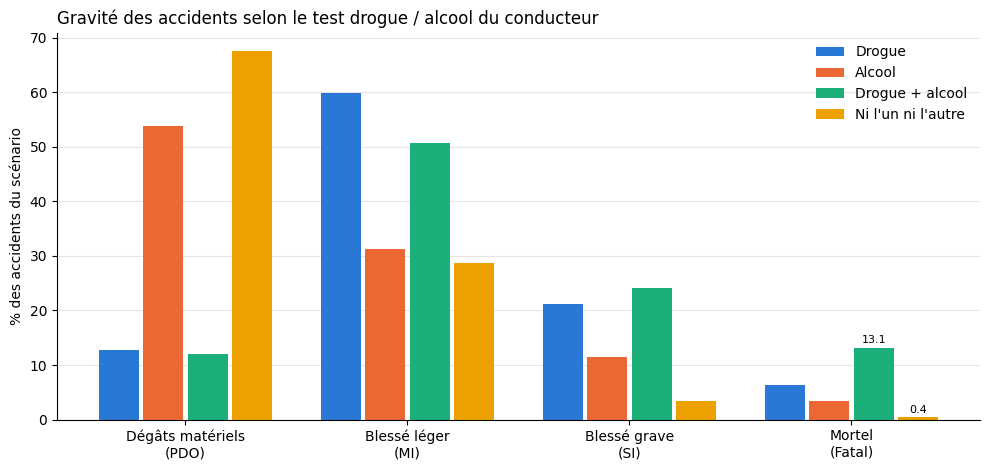

In [17]:
import matplotlib.pyplot as plt
import numpy as np
COUL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

def axes_propres(ax):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(True, axis="y", color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True)

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(rc.SEVERITES)); w = 0.2
for i, sc_ in enumerate(rc.SCENARIOS):
    vals = tableau.loc[rc.SEVERITES, sc_].values
    barres = ax.bar(x + (i - 1.5) * w, vals, w - 0.02, color=COUL[i], label=sc_)
    if sc_ in ("Drogue + alcool", "Ni l'un ni l'autre"):
        ax.bar_label(barres, labels=[f"{v:.1f}" if s == "4: Fatal" else "" for v, s in zip(vals, rc.SEVERITES)], fontsize=8, padding=2)
ax.set_xticks(x, ["Dégâts matériels\n(PDO)", "Blessé léger\n(MI)", "Blessé grave\n(SI)", "Mortel\n(Fatal)"])
ax.set_ylabel("% des accidents du scénario"); ax.set_title("Gravité des accidents selon le test drogue / alcool du conducteur", loc="left")
axes_propres(ax); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("results/gravite_drogue_alcool.png", dpi=130); plt.show()

In [18]:
mortel = tableau.loc["4: Fatal"]
grave = tableau.loc["3: SI"] + tableau.loc["4: Fatal"]
print("Part des accidents mortels         :", mortel.round(2).to_dict())
print("Part grave + mortel                :", grave.round(2).to_dict())
print("Risque relatif d'accident mortel   :", (mortel / mortel["Ni l'un ni l'autre"]).round(1).to_dict())

Part des accidents mortels         : {'Drogue': 6.31, 'Alcool': 3.42, 'Drogue + alcool': 13.09, "Ni l'un ni l'autre": 0.42}
Part grave + mortel                : {'Drogue': 27.4, 'Alcool': 14.88, 'Drogue + alcool': 37.25, "Ni l'un ni l'autre": 3.78}
Risque relatif d'accident mortel   : {'Drogue': 15.0, 'Alcool': 8.1, 'Drogue + alcool': 31.2, "Ni l'un ni l'autre": 1.0}


**Lecture.** Quand le conducteur n'a consommé ni drogue ni alcool, **0,4 %** des accidents sont mortels. Ce taux monte à ≈ **3,4 %** avec
l'alcool, ≈ **6,3 %** avec la drogue et ≈ **13 %** avec les deux : un accident est environ **8 fois** plus souvent mortel avec l'alcool,
**15 fois** avec la drogue et **31 fois** avec les deux. La part des accidents graves ou mortels suit la même progression.

**Précaution d'interprétation** (absente de l'article) : un conducteur n'est pas systématiquement testé, en particulier lors d'un accident
avec simples dégâts matériels ; il l'est presque toujours après un accident grave ou mortel. « Vide » mélange donc *négatif* et *non testé*.
Ce **biais de sélection** gonfle mécaniquement la part d'accidents graves parmi les positifs. Les données le suggèrent d'ailleurs :
54 % des accidents « alcool » sont de simples dégâts matériels, contre 13 % des accidents « drogue » — le dépistage d'alcool (éthylotest)
est courant même pour un accident léger, celui de drogue beaucoup moins. Le sens de l'effet est solide (et conforme à
la littérature), mais les rapports ×8 / ×15 / ×31 ne sont pas des risques causaux : il faudrait connaître les conducteurs testés négatifs.

## 4. Les mêmes requêtes avec les trois API

`src/road_crash.py` implémente chaque requête trois fois : **RDD** (fonctions Python sur des listes), **DataFrame** (fonctions Spark) et
**Spark SQL** (requête texte sur des vues temporaires). On vérifie que les trois donnent exactement le même résultat, puis on compare les temps
(médiane de 5 exécutions, après une exécution de chauffe).

In [19]:
print(open("src/road_crash.py", encoding="utf-8").read().split("# Requête 4")[1][:1800])

 : détail des usagers impliqués dans les accidents du quartier ADELAIDE (jointure Crash x Units)
# Date au format Année-Mois-JourDeLaSemaine : le jour exact n'est pas publié (donnée sensible).
# ----------------------------------------------------------------------------------------------------------
def adelaide_rdd(units_rdd, crash_rdd):
    u = units_rdd.map(parser_csv).map(lambda r: (r[U["REPORT_ID"]], (r[U["Sex"]], r[U["Age"]], r[U["Licence Type"]])))
    c = (crash_rdd.map(parser_csv).filter(lambda r: r[C["Suburb"]] == "ADELAIDE")
         .map(lambda r: (r[C["REPORT_ID"]], (f'{r[C["Year"]]}-{r[C["Month"]]}-{r[C["Day"]]}', r[C["Time"]],
                                             int(r[C["Total Cas"]])))))
    return sorted(c.join(u).map(lambda kv: (kv[0],) + kv[1][0] + kv[1][1]).collect(), key=str)


def adelaide_df(units_df, crash_df):
    res = (crash_df.filter(F.col("Suburb") == "ADELAIDE")
           .join(units_df, "REPORT_ID")
           .select("REPORT_ID", F.concat_ws("

In [20]:
REQUETES = {
    "Âge moyen par sexe": (lambda: rc.age_moyen_rdd(units_rdd), lambda: rc.age_moyen_df(units_df), lambda: rc.age_moyen_sql(spark)),
    "Victimes / quartier, sans permis (jointure)": (lambda: rc.sans_permis_rdd(units_rdd, crash_rdd),
                                                    lambda: rc.sans_permis_df(units_df, crash_df), lambda: rc.sans_permis_sql(spark)),
    "Gravité × drogue/alcool": (lambda: rc.gravite_scenarios_rdd(crash_rdd), lambda: rc.en_dict(rc.gravite_scenarios_df(crash_df)),
                                lambda: rc.en_dict(rc.gravite_scenarios_sql(spark))),
    "Détail des usagers à ADELAIDE (jointure)": (lambda: rc.adelaide_rdd(units_rdd, crash_rdd),
                                                 lambda: rc.adelaide_df(units_df, crash_df), lambda: rc.adelaide_sql(spark)),
}
import pandas as pd
mesures = []
for nom, (f_rdd, f_df, f_sql) in REQUETES.items():
    resultats, temps = [], []
    for f in (f_rdd, f_df, f_sql):
        f()                                                        # chauffe
        durees = []
        for _ in range(5):
            t0 = time.perf_counter(); r = f(); durees.append(time.perf_counter() - t0)
        resultats.append(r); temps.append(statistics.median(durees))
    identiques = resultats[0] == resultats[1] == resultats[2]
    mesures.append(dict(requete=nom, RDD=round(temps[0], 2), DataFrame=round(temps[1], 2), SQL=round(temps[2], 2),
                        identiques=identiques, taille_resultat=len(resultats[0])))
perf = pd.DataFrame(mesures).set_index("requete")
perf["RDD / DataFrame"] = (perf["RDD"] / perf["DataFrame"]).round(1)
perf.to_csv("results/temps_api.csv")
perf

,RDD,DataFrame,SQL,identiques,taille_resultat,RDD / DataFrame
requete,,,,,,
Âge moyen par sexe,3.99,1.91,2.19,True,2,2.1
"Victimes / quartier, sans permis (jointure)",14.09,5.12,3.65,True,752,2.8
Gravité × drogue/alcool,5.21,3.17,2.11,True,16,1.6
Détail des usagers à ADELAIDE (jointure),11.61,6.22,4.22,True,11965,1.9


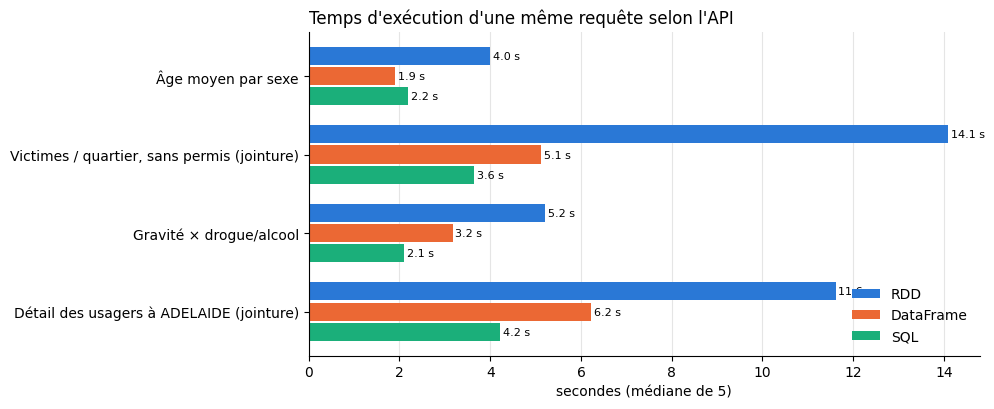

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(perf)); h = 0.26
for i, api in enumerate(["RDD", "DataFrame", "SQL"]):
    barres = ax.barh(y + (i - 1) * h, perf[api], h - 0.03, color=COUL[i], label=api)
    ax.bar_label(barres, fmt="%.1f s", fontsize=8, padding=2)
ax.set_yticks(y, perf.index); ax.invert_yaxis(); ax.set_xlabel("secondes (médiane de 5)")
ax.set_title("Temps d'exécution d'une même requête selon l'API", loc="left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(True, axis="x", color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("results/temps_api.png", dpi=130); plt.show()

Les trois API donnent **exactement le même résultat** pour chaque requête.

- **DataFrame et SQL** sont compilés par le même optimiseur (Catalyst) en des plans physiques équivalents : leurs écarts ne sont pas
  significatifs. Sur ce poste partagé (CPU hôte à 75–100 % pendant les mesures), une même requête varie de 1,5 à 8 s d'une exécution à l'autre.
- **L'API RDD** est la plus lente sur les **jointures**, environ 2 à 3 fois : chaque ligne est sérialisée vers un worker Python, découpée par
  `csv.reader`, puis la jointure fait transiter toutes les paires clé-valeur par le shuffle. Les DataFrames, eux, ne lisent que les colonnes
  utiles, filtrent avant de joindre et diffusent (*broadcast*) la petite table au lieu de la redistribuer, comme le montre le plan ci-dessous
  (`BroadcastHashJoin … LeftSemi`). Sur une simple agrégation, l'écart est plus faible.

In [22]:
spark.sql("SELECT c.Suburb, SUM(c.`Total Cas`) FROM crash c WHERE c.REPORT_ID IN "
          "(SELECT REPORT_ID FROM units WHERE `Licence Type` = 'Unlicenced') GROUP BY c.Suburb").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Suburb#54], functions=[sum(Total Cas#87)])
   +- Exchange hashpartitioning(Suburb#54, 8), ENSURE_REQUIREMENTS, [plan_id=5875]
      +- HashAggregate(keys=[Suburb#54], functions=[partial_sum(Total Cas#87)])
         +- Project [Suburb#54, cast(Total Cas#58 as int) AS Total Cas#87]
            +- BroadcastHashJoin [REPORT_ID#52], [REPORT_ID#17], LeftSemi, BuildRight, false, false
               :- FileScan csv [REPORT_ID#52,Suburb#54,Total Cas#58] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(8 paths)[file:/work/data/crash_data/2012_DATA_SA_Crash.csv, file:/work/data/cra..., PartitionFilters: [], PushedFilters: [], ReadSchema: struct<REPORT_ID:string,Suburb:string,Total Cas:string>
               +- BroadcastExchange HashedRelationBroadcastMode(List(input[0, string, true]),false), [plan_id=5870]
                  +- Project [REPORT_ID#17]
                     +- Filter (isnotnull(Li

## 5. Pour aller plus loin

### 5.1 Évolution annuelle

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


      accidents  victimes  morts  blessés graves
Year                                            
2012      22829      7479     94             761
2013      16675      7177     97             790
2014      16162      6982    108             711
2015      15431      6660    102             759
2016      16775      6565     86             692
2017      13237      6237    100             622
2018      13599      6124     80             576
2019      12964      6031    114             833


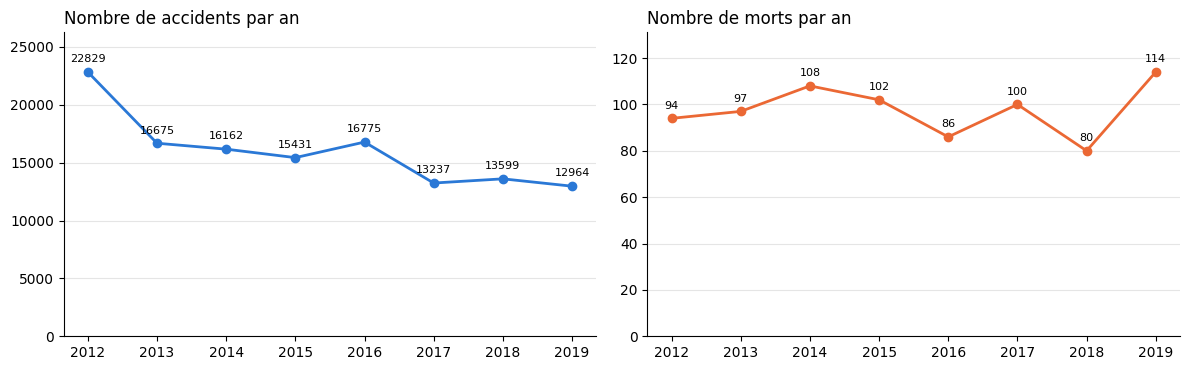

In [23]:
annuel = (crash_df.groupBy("Year").agg(F.count("*").alias("accidents"), F.sum("Total Cas").alias("victimes"),
                                      F.sum("Total Fats").alias("morts"), F.sum("Total SI").alias("blessés graves"))
          .orderBy("Year").toPandas().set_index("Year"))
print(annuel.to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, coul in [(axes[0], "accidents", COUL[0]), (axes[1], "morts", COUL[1])]:
    ax.plot(annuel.index, annuel[col], marker="o", ms=6, lw=2, color=coul)
    ax.set_title(f"Nombre de {col} par an", loc="left"); ax.set_ylim(0, annuel[col].max() * 1.15); axes_propres(ax)
    for x_, v in zip(annuel.index, annuel[col]): ax.annotate(f"{v}", (x_, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
plt.tight_layout(); plt.savefig("results/evolution_annuelle.png", dpi=130); plt.show()

### 5.2 Quand les accidents ont-ils lieu ? (heure × jour de la semaine)

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


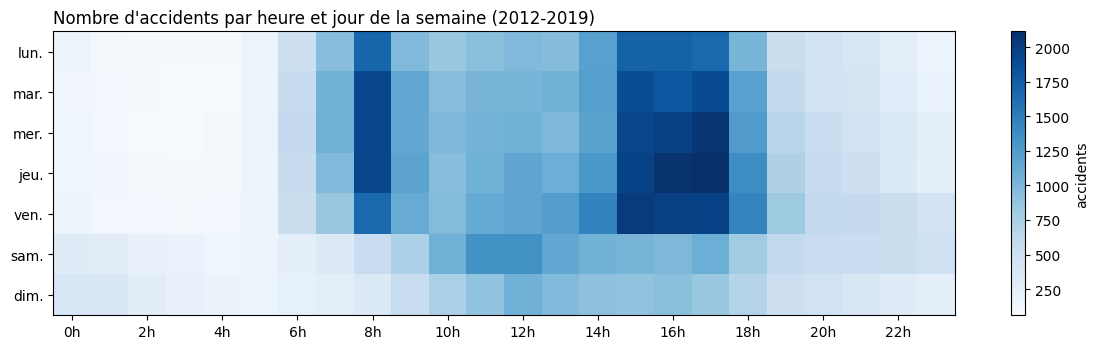

Morts pour 1000 accidents — nuit (22h-5h) : 12.4 | journée (8h-18h) : 5.1


In [24]:
JOURS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
JOURS_FR = ["lun.", "mar.", "mer.", "jeu.", "ven.", "sam.", "dim."]
heures = (crash_df.withColumn("heure", F.hour(F.to_timestamp(F.upper("Time"), "hh:mm a")))
          .groupBy("Day", "heure").agg(F.count("*").alias("n"), F.sum("Total Fats").alias("morts")).toPandas())
grille = heures.pivot(index="Day", columns="heure", values="n").reindex(JOURS).fillna(0)
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(grille.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), JOURS_FR); ax.set_xticks(range(0, 24, 2), [f"{h}h" for h in range(0, 24, 2)])
ax.set_title("Nombre d'accidents par heure et jour de la semaine (2012-2019)", loc="left")
plt.colorbar(im, ax=ax, label="accidents"); plt.tight_layout(); plt.savefig("results/heure_jour.png", dpi=130); plt.show()
nuit_we = heures[heures.heure.isin([22, 23, 0, 1, 2, 3, 4])]
print("Morts pour 1000 accidents — nuit (22h-5h) :", round(1000 * nuit_we.morts.sum() / nuit_we.n.sum(), 1),
      "| journée (8h-18h) :", round(1000 * heures[heures.heure.between(8, 18)].morts.sum() / heures[heures.heure.between(8, 18)].n.sum(), 1))

### 5.3 Gravité selon la limitation de vitesse

/usr/local/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


 vitesse  accidents  morts  morts pour 1000 accidents
      40       1852      6                        3.2
      50      34244     93                        2.7
      60      61035    146                        2.4
      70       4026     12                        3.0
      80      11013     88                        8.0
      90       2106     21                       10.0
     100       7413    180                       24.3
     110       5359    217                       40.5


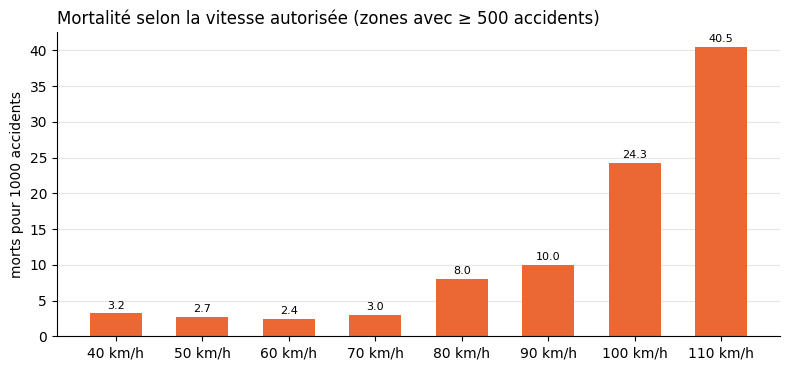

In [25]:
vitesse = (crash_df.filter(F.col("Area Speed").rlike("^[0-9]+$"))
           .withColumn("vitesse", F.col("Area Speed").cast("int"))
           .groupBy("vitesse").agg(F.count("*").alias("accidents"), F.sum("Total Fats").alias("morts"))
           .filter("accidents >= 500").orderBy("vitesse").toPandas())
vitesse["morts pour 1000 accidents"] = (1000 * vitesse.morts / vitesse.accidents).round(1)
print(vitesse.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3.8))
b = ax.bar(vitesse.vitesse.astype(str) + " km/h", vitesse["morts pour 1000 accidents"], color=COUL[1], width=0.6)
ax.bar_label(b, fmt="%.1f", fontsize=8, padding=2)
ax.set_ylabel("morts pour 1000 accidents"); ax.set_title("Mortalité selon la vitesse autorisée (zones avec ≥ 500 accidents)", loc="left")
axes_propres(ax); plt.tight_layout(); plt.savefig("results/vitesse.png", dpi=130); plt.show()

La mortalité par accident croît fortement avec la vitesse autorisée : les zones à 100–110 km/h sont nettement plus meurtrières que les zones
urbaines à 50–60 km/h, alors que ces dernières concentrent la majorité des accidents. Les accidents sont surtout concentrés aux heures de
pointe en semaine (8h et 15h–18h), mais ceux de la nuit sont plus graves.

## 6. Tests

`tests/test_road_crash.py` construit un **mini jeu de données** (4 accidents, 6 usagers) dont on connaît les réponses, avec des cas pièges :
champs contenant des virgules, âge masqué `XXX`, âge vide, sexe inconnu, deux conducteurs sans permis dans le même accident,
conducteur positif à la drogue **et** à l'alcool. Pour chaque requête, les trois API doivent donner la réponse attendue.

In [26]:
spark.stop()
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--color=no", "-p", "no:cacheprovider", "tests"], capture_output=True, text=True)
print(r.stdout[-1800:])

============================= test session starts ==============================
platform linux -- Python 3.12.15, pytest-9.1.1, pluggy-1.6.0 -- /usr/local/bin/python3.12
rootdir: /work
plugins: anyio-4.15.1, platformdirs-4.13.0
collecting ... collected 6 items

tests/test_road_crash.py::test_chargement PASSED                         [ 16%]
tests/test_road_crash.py::test_parseur_csv_respecte_les_guillemets PASSED [ 33%]
tests/test_road_crash.py::test_age_moyen PASSED                          [ 50%]
tests/test_road_crash.py::test_sans_permis_un_accident_compte_une_fois PASSED [ 66%]
tests/test_road_crash.py::test_gravite_scenarios PASSED                  [ 83%]
tests/test_road_crash.py::test_adelaide PASSED                           [100%]

======================== 6 passed in 114.49s (0:01:54) =========================



## 7. Regard critique sur l'article

Reproduire l'étude, puis vérifier que les trois API donnent le même résultat, a fait apparaître plusieurs problèmes dans le code d'origine :

| # | Dans l'article | Problème | Ce qu'on a fait |
|---|---|---|---|
| 1 | RDD : `line.split(',')` | 21 379 accidents (16,7 %) ont un champ contenant une virgule (`CURVED, VIEW OPEN`, `CC OF NORWOOD,PAYNEHAM & ST PETERS`…) : les colonnes suivantes sont décalées ; l'année ou le nombre de victimes sont lus de travers pour plus de 5 000 accidents | parseur `csv` qui respecte les guillemets ; test dédié |
| 2 | « partition sur `Lic State` » | le code utilise l'index 3, qui est `Veh Reg State` (immatriculation du véhicule), pas l'État du permis | partition nommée correctement |
| 3 | `sum('Total Cas')` après la jointure Crash × Units | `Total Cas` est une donnée de l'accident, répétée pour chaque véhicule : un accident avec deux conducteurs sans permis est compté deux fois (39 accidents concernés) | sommer sur les `REPORT_ID` distincts ; test dédié |
| 4 | requête RDD/DataFrame/SQL n° 2 « victimes des conducteurs sans permis » | les trois versions ne calculent ni la même chose ni ce qui est annoncé : elles **excluent** les permis inconnus au lieu de **garder** les `Unlicenced`, et utilisent `count` au lieu de `sum` | une seule définition, implémentée trois fois et testée |
| 5 | pourcentages par UDF Python, quatre blocs recopiés | lent (sérialisation Python) et source d'erreurs de copier-coller | une requête avec une fonction de fenêtre |
| 6 | `sortByKey().collect()[0:5]` | rapatrie tout le RDD sur le driver pour en garder 5 éléments | `take(5)` |
| 7 | interprétation drogue / alcool | ne tient pas compte du fait que les conducteurs ne sont pas tous testés | biais de sélection discuté |

Aucun de ces points ne remet en cause la conclusion principale de l'article (drogue et alcool sont associés à des accidents bien plus graves),
mais les points 1, 3 et 4 donnent des **chiffres faux sans aucun message d'erreur**. C'est un argument fort pour écrire chaque requête de
deux façons indépendantes et les confronter par des tests, comme on l'a fait ici.

## 8. Conclusion

- **Reproduction.** On retrouve les résultats de l'article : 127 672 accidents et 272 591 usagers sur 2012–2019, un âge moyen de 40,8 ans
  (hommes) et 40,1 ans (femmes), et la même répartition des accidents par gravité. Les deux seuls écarts (victimes des conducteurs sans permis)
  viennent d'erreurs de l'article.
- **Sécurité routière.**
  - Un accident est mortel dans 0,4 % des cas sans drogue ni alcool, contre 3,4 % avec alcool, 6,3 % avec drogue et 13 % avec les deux.
    L'association est forte, même si un biais de dépistage en exagère l'ampleur.
  - La mortalité par accident est 10 à 17 fois plus élevée sur les routes à 100–110 km/h qu'en ville, et environ 2,4 fois plus élevée la nuit qu'en journée.
  - Le nombre d'accidents baisse de 2012 à 2019 (de 22 829 à 12 964), mais pas le nombre de morts (80 à 114 par an).
- **Spark.**
  - Les trois API expriment les mêmes requêtes et donnent exactement les mêmes résultats.
  - L'API **RDD** offre un contrôle total, par exemple pour un partitionnement personnalisé, mais elle est verbeuse, fragile (découpage CSV, indices
    de colonnes) et plus lente en Python.
  - **DataFrame et SQL** sont plus courts, plus sûrs (colonnes nommées et typées, CSV correctement lu) et plus rapides, grâce à Catalyst :
    ils ne lisent que les colonnes utiles et diffusent la petite table dans les jointures.
  - Comme au TP2, l'API DataFrame/SQL est donc le bon choix par défaut en PySpark.
- **Passage à l'échelle.** Sur 80 Mo, une machine suffit. Le même code s'exécuterait sans modification sur un cluster et sur des années de données
  de toute l'Australie : seul le *master* de la SparkSession change. Les seules étapes non distribuées sont les conversions `toPandas()`
  pour les graphiques, appliquées à des résultats déjà agrégés de quelques lignes.